In [1]:
import config

from forklens import train
from forklens.dataset import ShapeDataset
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

-- This is a toy experiment using not optimal parameters and toy simulation.

-- The setup is defined in the Config.py under the same path, inlcuding stamp size, pixel scale and so on.

-- To be able to run this, you need to modify two lines in the source code of Forklens, due to the change in the stamp size. In the ForkCNN class in networks.py, 1. change line 108 into "nn.Linear(1536, 512),", 2. comment line 117 as "# x = self.avgpool(x)".

In [2]:
# Load data catalog
with fits.open('../../data/csst_catalog_example.fits') as f:
    cat = f[0].data
cut_idx = np.where((cat[:,0]>0.1)&(cat[:,1]<25))[0]
size_cat = cat[cut_idx,0]
mag_cat = cat[cut_idx,1]

In [3]:
# Generate data
def dataframe(num, seed=12345):
    
    num = int(num/2)
    
    rng1 = np.random.RandomState(seed)
    idx = rng1.randint(0,mag_cat.shape[0],size=num)
    Gal_Hlr   = size_cat[idx]
    Gal_Hlr   = np.concatenate((Gal_Hlr, Gal_Hlr), axis=0)
    Gal_Mag   = mag_cat[idx]
    Gal_Mag   = np.concatenate((Gal_Mag, Gal_Mag), axis=0)
    
    rng2 = np.random.RandomState(seed+1)
    Gal_Theta = rng2.random(num*2)*2*np.pi
    Gal_ELL = np.sqrt(rng2.random(num*2))*0.999
    e1 = Gal_ELL*np.sin(2*Gal_Theta)
    e2 = Gal_ELL*np.cos(2*Gal_Theta)

    rng3 = np.random.RandomState(seed+2)
    PSF_randint = rng3.randint(0,10000,size=num)
    PSF_randint = np.concatenate((PSF_randint, PSF_randint), axis=0)
    
    gal_pars = {}
    gal_pars["e1"] = e1
    gal_pars["e2"] = e2
    gal_pars["hlr_disk"] = Gal_Hlr
    gal_pars["mag_i"] = Gal_Mag
    
    psf_pars = {}
    psf_pars['randint'] = PSF_randint
    
    return gal_pars, psf_pars

## Training

In [4]:
# Get data loader
nSims = 50000
GalCat, PSFCat = dataframe(nSims, seed=12345)
train_ds = ShapeDataset(GalCat, PSFCat)

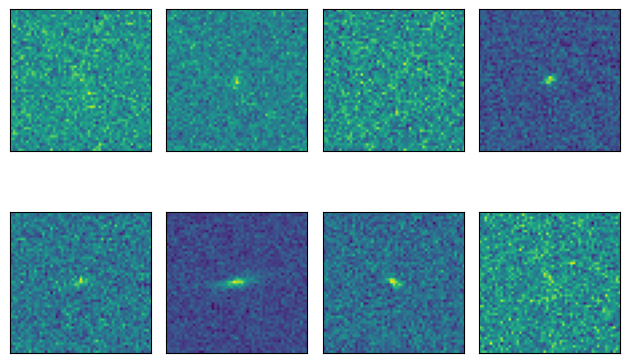

In [7]:
train_dl = DataLoader(train_ds)

num_samples = 8
random_indices = np.random.choice(range(nSims), size=num_samples, replace=False)

for i in range(num_samples):
    plt.subplot(2,4,i+1)
    gal_im = train_dl.dataset[random_indices[i]]['gal_image'][0]
    plt.imshow(gal_im)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()

In [8]:
# Train the network
tr = train.Train()
train_log = tr.run(train_ds, show_log=False);

Train_dl: 180 Validation_dl: 20
Begin training ...


/project/ls-gruen/users/zekang.zhang/envs/sims1/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Finish training !


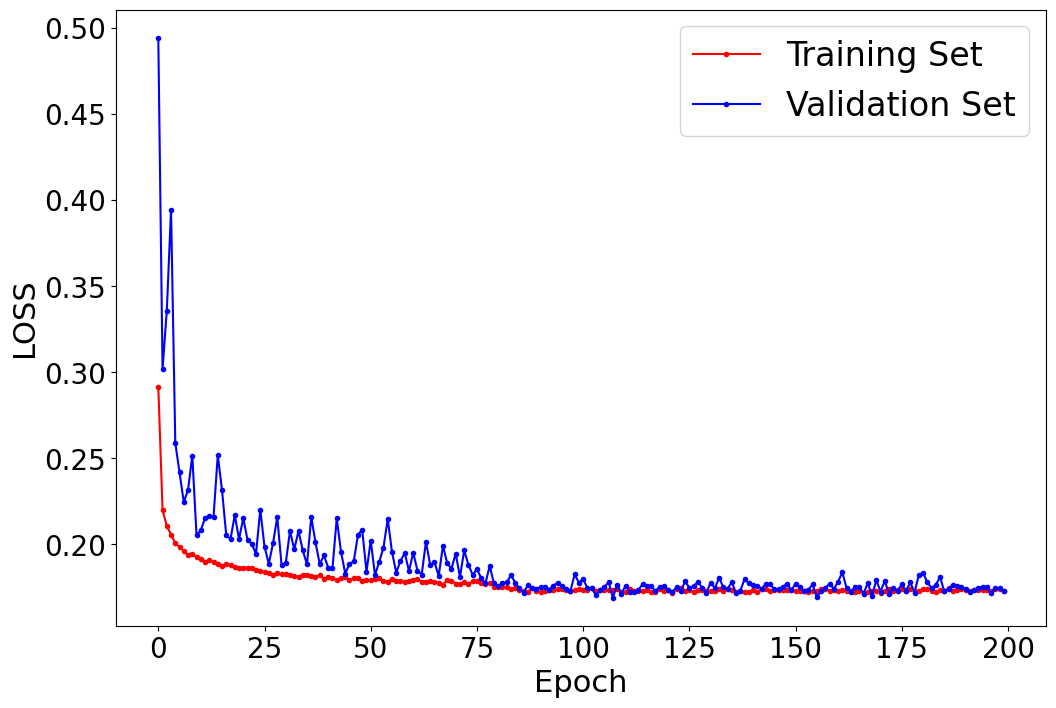

In [11]:
train_losses, valid_losses = train_log

plt.figure(figsize=(12,8))

plt.plot(train_losses, 'r.-', label="Training Set")
plt.plot(valid_losses, 'b.-', label='Validation Set')

plt.xlabel("Epoch", fontsize=22)
plt.ylabel("LOSS", fontsize=22)
plt.tick_params(axis='both',which='major',labelsize=20)
plt.legend(fontsize=24)

# plt.ylim(0.2,0.4)

## Test

In [12]:
ts = train.Train()
model_file = "./model/test_model149"
model = ts.load_model(path=model_file,strict=True)

/project/ls-gruen/users/zekang.zhang/envs/sims1/lib/python3.9/site-packages/forklens-0.0.1-py3.9.egg/forklens/train.py:60: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


In [13]:
# Get data loader
nSims = 5000
GalCat, PSFCat = dataframe(nSims, seed=11111)
test_ds = ShapeDataset(GalCat, PSFCat)
test_dl = DataLoader(test_ds, 
                      batch_size=config.train['batch_size'], 
                      num_workers=config.train['workers'])

pred, true, snr, loss = tr._predictFunc(test_dl,model)
print('Test LOSS:',loss)
diff = pred - true

Test LOSS: 0.17452112513008858


In [14]:
# "True" S/N of galaxies
snr[snr[:,1]>50,1] =50

Text(0.5, 1.1, 'Full sample')

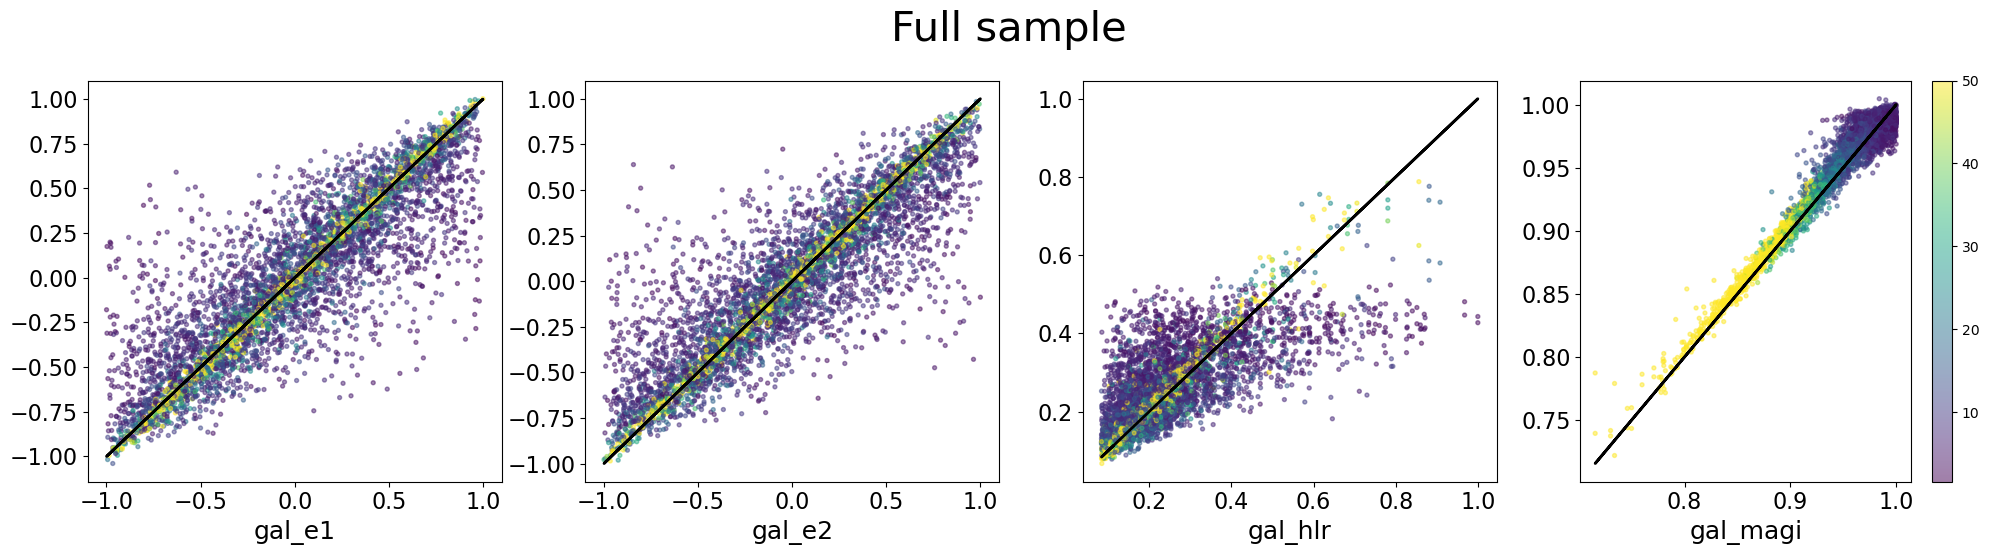

In [15]:
title = ['gal_e1','gal_e2','gal_hlr','gal_magi']

idx = np.where(snr[:,1]>0)[0]

plt.figure(figsize=(20,5))
for i in range(4): 
    plt.subplot(1,4,i+1)
    plt.xlabel(title[i],fontsize=18)
    plt.scatter(true[idx,i+1], pred[idx,i+1],c=snr[:,1],s=8,alpha=0.5)
    plt.plot(true[idx,i+1], true[idx,i+1], 'k-', linewidth=2)
    plt.tick_params(axis='both',which='major',labelsize=16)
    
plt.colorbar()
plt.tight_layout()
plt.suptitle('Full sample',fontsize=30,y=1.1)

Text(0.5, 1.1, 'S/N > 10')

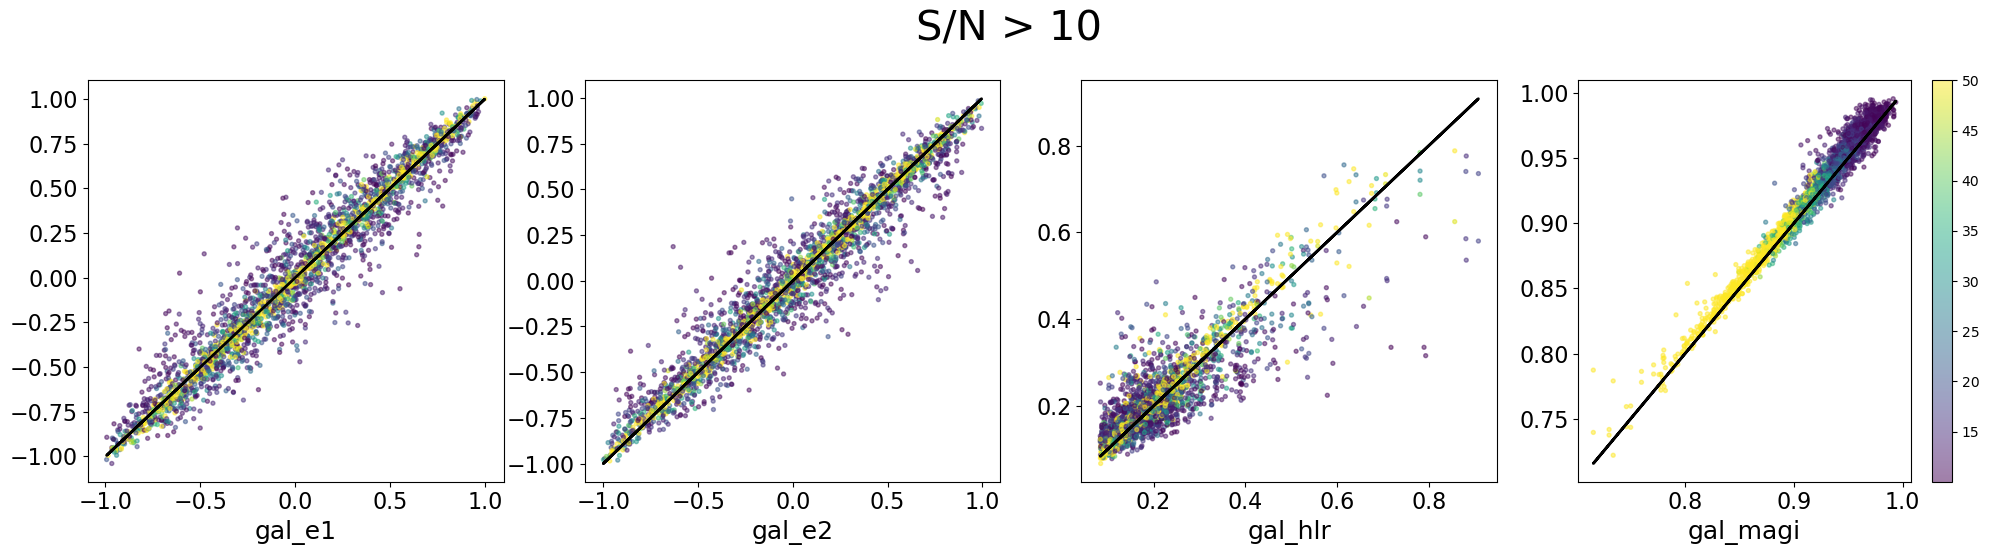

In [16]:
title = ['gal_e1','gal_e2','gal_hlr','gal_magi']

idx = np.where(snr[:,1]>10)[0]

plt.figure(figsize=(20,5))
for i in range(4): 
    plt.subplot(1,4,i+1)
    plt.xlabel(title[i],fontsize=18)
    plt.scatter(true[idx,i+1], pred[idx,i+1],c=snr[idx,1],s=8,alpha=0.5)
    plt.plot(true[idx,i+1], true[idx,i+1], 'k-', linewidth=2)
    plt.tick_params(axis='both',which='major',labelsize=16)
    
plt.colorbar()
plt.tight_layout()
plt.suptitle('S/N > 10',fontsize=30,y=1.1)